In [1]:
%pip install rasterio matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import rasterio
import matplotlib
import torch

print("Rasterio:", rasterio.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

Rasterio: 1.4.4
PyTorch: 2.9.1+cu128
GPU available: True


In [3]:
# Evaluate the checkpoint selected using validation performance.%pip install rasterio matplotlib
%run evaluate_baseline.py --run-dir results/winter9_20261106_094944_502500 --batch-size 8

Test patches: 5050 | device: cuda | checkpoint epoch: 9
Test 1/632 | elapsed 0.0 min
Test 100/632 | elapsed 0.3 min
Test 200/632 | elapsed 0.6 min
Test 300/632 | elapsed 0.9 min
Test 400/632 | elapsed 1.1 min
Test 500/632 | elapsed 1.4 min
Test 600/632 | elapsed 1.7 min
Test 632/632 | elapsed 1.8 min

Test OA: 53.50%
Test mIoU: 30.55%
Forest            IoU: 0.168 | F1: 0.287
Shrubland         IoU: 0.080 | F1: 0.149
Savanna           IoU: 0.431 | F1: 0.602
Grassland         IoU: 0.118 | F1: 0.210
Wetland           IoU: 0.076 | F1: 0.141
Cropland          IoU: 0.500 | F1: 0.667
Urban/Built-up    IoU: 0.604 | F1: 0.753
Barren            IoU: 0.280 | F1: 0.438
Water             IoU: 0.493 | F1: 0.660
Saved evaluation: /home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558


evaluate_baseline.py
test.csv
test_classes.csv
test_confusion.csv
test_confusion.npy
test_confusion.png
test_summary.json


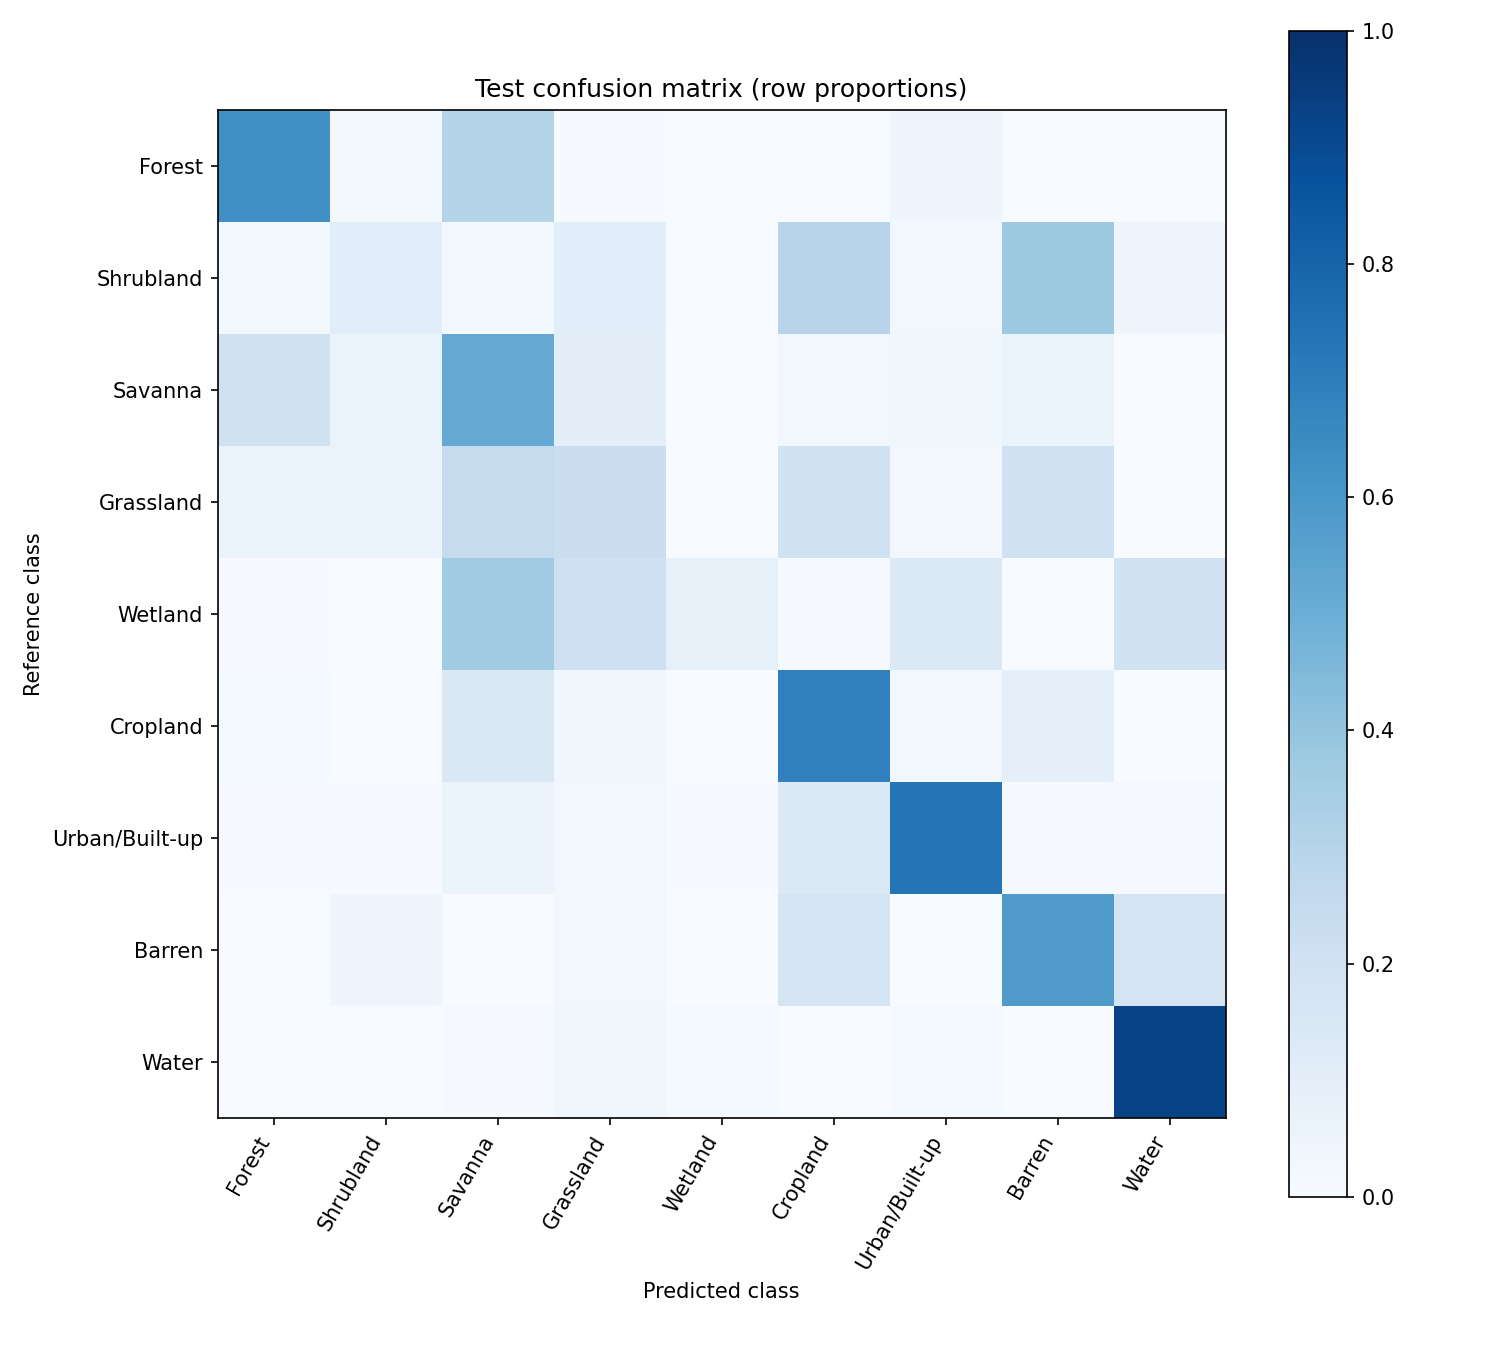

In [4]:
from pathlib import Path
from IPython.display import Image, display

# The folder printed at the end of your successful evaluation.
evaluation_dir = Path(
    "results/winter9_20261106_094944_502500/"
    "test_evaluation_20261107_084224_251734"
)

# List the saved evaluation files.
for file in sorted(evaluation_dir.iterdir()):
    print(file.name)

# Display any saved PNG figures.
for file in sorted(evaluation_dir.glob("*.png")):
    display(Image(filename=str(file)))

In [5]:
from pathlib import Path
import os

eval_dir = Path(
    "/home/jovyan/vault/DeepLearningPro/results/"
    "winter9_20261106_094944_502500/"
    "test_evaluation_20261109_091640_449558"
)

print("Evaluation directory:", eval_dir)
print("Exists:", eval_dir.exists())

if eval_dir.exists():
    print("\nFiles generated:")
    for p in sorted(eval_dir.rglob("*")):
        if p.is_file():
            print(f"  {p.relative_to(eval_dir)}")

print("\nFinal test metrics:")
print("Test OA   : 53.50%")
print("Test mIoU : 30.55%")

Evaluation directory: /home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558
Exists: True

Files generated:
  evaluate_baseline.py
  test.csv
  test_classes.csv
  test_confusion.csv
  test_confusion.npy
  test_confusion.png
  test_summary.json

Final test metrics:
Test OA   : 53.50%
Test mIoU : 30.55%


In [6]:
from pathlib import Path
import pandas as pd

# Find the latest test evaluation directory
results_root = Path("/home/jovyan/vault/DeepLearningPro/results")

eval_dirs = sorted(
    results_root.glob("winter9_*/test_evaluation_*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

print("Latest evaluation directory:")
print(eval_dirs[0] if eval_dirs else "NOT FOUND")

if eval_dirs:
    eval_dir = eval_dirs[0]

    print("\n=== FILES IN EVALUATION DIRECTORY ===")
    for f in sorted(eval_dir.rglob("*")):
        if f.is_file():
            print(f"  {f.name}")

    print("\n=== CSV FILES ===")
    for csv_file in sorted(eval_dir.rglob("*.csv")):
        try:
            df = pd.read_csv(csv_file)
            print(f"\n{csv_file.name}")
            print(df.head(10).to_string(index=False))
        except Exception as e:
            print(f"{csv_file.name}: could not read ({e})")

Latest evaluation directory:
/home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558

=== FILES IN EVALUATION DIRECTORY ===
  evaluate_baseline.py
  test.csv
  test_classes.csv
  test_confusion.csv
  test_confusion.npy
  test_confusion.png
  test_summary.json

=== CSV FILES ===

test.csv
                                                                image                                                                 label  scene
data/extracted/ROIs2017_winter/s1_117/ROIs2017_winter_s1_117_p100.tif data/extracted/ROIs2017_winter/lc_117/ROIs2017_winter_lc_117_p100.tif s1_117
data/extracted/ROIs2017_winter/s1_117/ROIs2017_winter_s1_117_p101.tif data/extracted/ROIs2017_winter/lc_117/ROIs2017_winter_lc_117_p101.tif s1_117
data/extracted/ROIs2017_winter/s1_117/ROIs2017_winter_s1_117_p102.tif data/extracted/ROIs2017_winter/lc_117/ROIs2017_winter_lc_117_p102.tif s1_117
data/extracted/ROIs2017_winter/s1_117/ROIs2017_winter_s1_117_p103.

In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json

# Evaluation directory
eval_dir = Path(
    "/home/jovyan/vault/DeepLearningPro/results/"
    "winter9_20261106_094944_502500/"
    "test_evaluation_20261109_091640_449558"
)

# Load per-class results
classes_df = pd.read_csv(eval_dir / "test_classes.csv")

# Load overall summary
with open(eval_dir / "test_summary.json", "r") as f:
    summary = json.load(f)

print("=" * 60)
print("FINAL TEST EVALUATION")
print("=" * 60)

print(f"\nTest Overall Accuracy : {summary.get('overall_accuracy', 0) * 100:.2f}%")
print(f"Test Mean IoU         : {summary.get('mean_iou', 0) * 100:.2f}%")

print("\nPER-CLASS RESULTS")
print("-" * 60)

display(
    classes_df[
        ["class_id", "class_name", "iou", "f1"]
    ].style.format({
        "iou": "{:.4f}",
        "f1": "{:.4f}"
    })
)

# Plot IoU by class
plt.figure(figsize=(10, 5))

plt.bar(
    classes_df["class_name"],
    classes_df["iou"] * 100
)

plt.ylabel("IoU (%)")
plt.xlabel("Land-cover class")
plt.title("Test IoU by Land-cover Class")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

iou_plot = eval_dir / "final_test_iou_by_class.png"
plt.savefig(iou_plot, dpi=200, bbox_inches="tight")
plt.show()

# Plot F1 by class
plt.figure(figsize=(10, 5))

plt.bar(
    classes_df["class_name"],
    classes_df["f1"] * 100
)

plt.ylabel("F1 Score (%)")
plt.xlabel("Land-cover class")
plt.title("Test F1 Score by Land-cover Class")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

f1_plot = eval_dir / "final_test_f1_by_class.png"
plt.savefig(f1_plot, dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(iou_plot)
print(f1_plot)

FINAL TEST EVALUATION

Test Overall Accuracy : 53.50%
Test Mean IoU         : 30.55%

PER-CLASS RESULTS
------------------------------------------------------------


,class_id,class_name,iou,f1
0,0,Forest,0.1678,0.2873
1,1,Shrubland,0.0804,0.1489
2,2,Savanna,0.4306,0.6020
3,3,Grassland,0.1175,0.2103
4,4,Wetland,0.0761,0.1414
5,5,Cropland,0.4998,0.6665
6,6,Urban/Built-up,0.6045,0.7535
7,7,Barren,0.2801,0.4376
8,8,Water,0.4927,0.6601



Saved:
/home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558/final_test_iou_by_class.png
/home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558/final_test_f1_by_class.png


In [8]:
from pathlib import Path
import pandas as pd
import json
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# FINAL PROJECT RESULTS SUMMARY
# ---------------------------------------------------------

eval_dir = Path(
    "/home/jovyan/vault/DeepLearningPro/results/"
    "winter9_20261106_094944_502500/"
    "test_evaluation_20261109_091640_449558"
)

# Load results
classes_df = pd.read_csv(eval_dir / "test_classes.csv")

with open(eval_dir / "test_summary.json", "r") as f:
    summary = json.load(f)

# Overall metrics
accuracy = summary.get("overall_accuracy", 0)
miou = summary.get("mean_iou", 0)

print("=" * 70)
print("FINAL DEEP LEARNING PROJECT RESULTS")
print("=" * 70)

print(f"\nTest Overall Accuracy : {accuracy * 100:.2f}%")
print(f"Test Mean IoU         : {miou * 100:.2f}%")

# ---------------------------------------------------------
# BEST / WORST CLASSES
# ---------------------------------------------------------

best_iou = classes_df.loc[classes_df["iou"].idxmax()]
worst_iou = classes_df.loc[classes_df["iou"].idxmin()]

best_f1 = classes_df.loc[classes_df["f1"].idxmax()]
worst_f1 = classes_df.loc[classes_df["f1"].idxmin()]

print("\n" + "-" * 70)
print("BEST / WORST CLASS PERFORMANCE")
print("-" * 70)

print(
    f"Best IoU  : {best_iou['class_name']} "
    f"({best_iou['iou'] * 100:.2f}%)"
)

print(
    f"Worst IoU : {worst_iou['class_name']} "
    f"({worst_iou['iou'] * 100:.2f}%)"
)

print(
    f"Best F1   : {best_f1['class_name']} "
    f"({best_f1['f1'] * 100:.2f}%)"
)

print(
    f"Worst F1  : {worst_f1['class_name']} "
    f"({worst_f1['f1'] * 100:.2f}%)"
)

# ---------------------------------------------------------
# COMPLETE TABLE
# ---------------------------------------------------------

print("\n" + "-" * 70)
print("PER-CLASS PERFORMANCE")
print("-" * 70)

display(
    classes_df[
        ["class_id", "class_name", "reference_pixels",
         "predicted_pixels", "iou", "f1"]
    ].style.format({
        "iou": "{:.4f}",
        "f1": "{:.4f}"
    })
)

# ---------------------------------------------------------
# SAVE FINAL SUMMARY
# ---------------------------------------------------------

final_summary = {
    "test_accuracy": float(accuracy),
    "test_miou": float(miou),
    "best_iou_class": str(best_iou["class_name"]),
    "best_iou": float(best_iou["iou"]),
    "worst_iou_class": str(worst_iou["class_name"]),
    "worst_iou": float(worst_iou["iou"]),
    "best_f1_class": str(best_f1["class_name"]),
    "best_f1": float(best_f1["f1"]),
    "worst_f1_class": str(worst_f1["class_name"]),
    "worst_f1": float(worst_f1["f1"])
}

summary_path = eval_dir / "FINAL_PROJECT_RESULTS.json"

with open(summary_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print("\n" + "=" * 70)
print("FINAL RESULTS FILE SAVED")
print("=" * 70)
print(summary_path)

FINAL DEEP LEARNING PROJECT RESULTS

Test Overall Accuracy : 53.50%
Test Mean IoU         : 30.55%

----------------------------------------------------------------------
BEST / WORST CLASS PERFORMANCE
----------------------------------------------------------------------
Best IoU  : Urban/Built-up (60.45%)
Worst IoU : Wetland (7.61%)
Best F1   : Urban/Built-up (75.35%)
Worst F1  : Wetland (14.14%)

----------------------------------------------------------------------
PER-CLASS PERFORMANCE
----------------------------------------------------------------------


,class_id,class_name,reference_pixels,predicted_pixels,iou,f1
0,0,Forest,9632665,32726595,0.1678,0.2873
1,1,Shrubland,29701832,13813520,0.0804,0.1489
2,2,Savanna,119223347,84082173,0.4306,0.6020
3,3,Grassland,23685718,26112705,0.1175,0.2103
4,4,Wetland,3304568,701741,0.0761,0.1414
5,5,Cropland,70344964,75258794,0.4998,0.6665
6,6,Urban/Built-up,38777578,36855145,0.6045,0.7535
7,7,Barren,27876616,46221736,0.2801,0.4376
8,8,Water,8409512,15184391,0.4927,0.6601



FINAL RESULTS FILE SAVED
/home/jovyan/vault/DeepLearningPro/results/winter9_20261106_094944_502500/test_evaluation_20261109_091640_449558/FINAL_PROJECT_RESULTS.json
